In [24]:
import pandas as pd
import numpy as np
from scipy.stats import norm
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt

df = pd.read_csv("../data/crashes_clean.csv", low_memory = False, parse_dates=['crash_dt'])
df.head()

,CRASH DATE,CRASH TIME,BOROUGH,ZIP CODE,LATITUDE,LONGITUDE,LOCATION,ON STREET NAME,CROSS STREET NAME,OFF STREET NAME,...,VEHICLE TYPE CODE 4,VEHICLE TYPE CODE 5,crash_dt,year,month,weekday,hour,injury_crash,fatal_crash,borough_filled
0,12/31/2025,21:23,BROOKLYN,11236.0,40.643660,-73.900665,"(40.64366, -73.900665)",ROCKAWAY PKWY,NaN,FLATLANDS AVE,...,NaN,NaN,2025-12-31 21:23:00,2025,12,Wednesday,21,True,False,BROOKLYN
1,12/31/2025,12:15,BRONX,10452.0,40.837140,-73.920480,"(40.83714, -73.92048)",E 168 ST,NaN,RIVER AVE,...,NaN,NaN,2025-12-31 12:15:00,2025,12,Wednesday,12,False,False,BRONX
2,12/31/2025,13:30,NaN,NaN,40.665054,-73.735990,"(40.665054, -73.73599)",NaN,241-42 S CONDUIT AVE,NaN,...,NaN,NaN,2025-12-31 13:30:00,2025,12,Wednesday,13,False,False,QUEENS
3,12/31/2025,05:20,BROOKLYN,11207.0,40.657814,-73.896126,"(40.657814, -73.896126)",LINDEN BLVD,NaN,WILLIAMS AVE,...,NaN,NaN,2025-12-31 05:20:00,2025,12,Wednesday,5,False,False,BROOKLYN
4,12/31/2025,22:03,BRONX,10468.0,40.859978,-73.900790,"(40.859978, -73.90079)",E 184 ST,NaN,MORRIS AVE,...,NaN,NaN,2025-12-31 22:03:00,2025,12,Wednesday,22,False,False,BRONX


In [25]:
by_year = df.groupby('year').size()
print(by_year)
by_year.pct_change()

year
2023    96608
2024    91316
2025    85559
dtype: int64


year
2023         NaN
2024   -0.054778
2025   -0.063045
dtype: float64

In [26]:
valid_time = df['CRASH TIME'] != '00:00' #remove 00:00 placeholder
by_hour = df[valid_time].groupby('hour').size() #group by hour
by_hour

hour
0      7390
1      6559
2      5263
3      4817
4      5525
5      5665
6      7618
7     10407
8     14451
9     12674
10    11993
11    12445
12    13386
13    13570
14    15518
15    15950
16    16870
17    17029
18    15221
19    13750
20    12067
21    11157
22    10089
23     9071
dtype: int64

-Lowest crash count at 3AM (4817) compared to highest crash count at 5PM (17029). About a 3 times difference.
-Morning bump at 8AM, then dipped, then highest at 4-5PM. More cars on the road leads to more crashes in total.

In [27]:
# How bad are the crashes? (severity)
# Look at injury_crash and fatal_crash
by_hour_injury = df[valid_time].groupby('hour')['injury_crash'].mean()
print(by_hour_injury)

by_hour_fatal = df[valid_time].groupby('hour')['fatal_crash'].mean()
by_hour_fatal

hour
0     0.411096
1     0.371398
2     0.358731
3     0.345028
4     0.354027
5     0.358164
6     0.392754
7     0.413760
8     0.400457
9     0.394351
10    0.386559
11    0.409562
12    0.411251
13    0.437362
14    0.446707
15    0.459812
16    0.460047
17    0.469141
18    0.485973
19    0.491055
20    0.480070
21    0.477996
22    0.458519
23    0.427075
Name: injury_crash, dtype: float64


hour
0     0.005277
1     0.004421
2     0.006080
3     0.007266
4     0.006335
5     0.005649
6     0.004463
7     0.001634
8     0.001799
9     0.001578
10    0.001918
11    0.001527
12    0.001868
13    0.001842
14    0.001869
15    0.001505
16    0.001126
17    0.001703
18    0.002956
19    0.002545
20    0.002983
21    0.004481
22    0.004163
23    0.004079
Name: fatal_crash, dtype: float64

Late-night crashes are the least likely to cause injury (34.5% at 3 AM vs 49% at 7 PM) but the most likely to be fatal (0.73% at 3 AM vs 0.11% at 4 PM, about 6 times higher). Fewer crashes happen at night, but when they're serious, they're much deadlier.

In [28]:
by_hour_fatal_total = df[valid_time].groupby('hour')['fatal_crash'].sum()
by_hour_fatal_total

hour
0     39
1     29
2     32
3     35
4     35
5     32
6     34
7     17
8     26
9     20
10    23
11    19
12    25
13    25
14    29
15    24
16    19
17    29
18    45
19    35
20    36
21    50
22    42
23    37
Name: fatal_crash, dtype: int64

Counts are small per hour compared to total deaths so variance is large for comparing per hour. Let's group the hours together into larger blocks so each group has more data and more defensible. 
For example, from 0-5 and the rest of the day.

In [29]:
df['night'] = df['hour'].between(0, 5)
df[valid_time].groupby('night')['fatal_crash'].agg(['sum', 'mean'])

,sum,mean
night,,
False,535,0.002294
True,202,0.005736


The rate of fatality for night time is 0.57% compared to 0.23% for day time. Is this result significant? We can perform a two proportion z-test to find out.

In [30]:
night_table = df[valid_time].groupby('night')['fatal_crash'].agg(['sum', 'size', 'mean'])
night_table

,sum,size,mean
night,,,
False,535,233266,0.002294
True,202,35219,0.005736


In [31]:
# H0 : Night and day time have the same fatality rate
# Ha : Night and day time do not have the same fatality rate
#  - p̂₁, p̂₂ = the two fatal rates (night, day)
#  - p̂ = pooled rate = total fatal ÷ total crashes, i.e. (202 + 535) ÷ (35,219 + 233,266)
#  - SE = √[ p̂(1 − p̂)(1/n₁ + 1/n₂) ]
#  - z = (p̂₁ − p̂₂) ÷ SE

p_night = night_table.loc[True, 'mean']
p_day = night_table.loc[False, 'mean']
p_pooled = night_table['sum'].sum() / night_table['size'].sum()
se = np.sqrt(p_pooled * (1 - p_pooled) * (1 / night_table.loc[True, 'size'] + 1 / night_table.loc[False, 'size']))
z = (p_night - p_day) / se
print(z)

p_value = 2 * norm.sf(z)
p_value



11.507764363454509


np.float64(1.205633818929965e-30)

z = 11.5 and p < 0.001, so we reject H₀: night crashes (midnight–6 AM) are significantly more likely to be fatal than day crashes, 0.57% vs 0.23%, about 2.5 times higher. Combined with the lower night injury rate, night crashes are fewer and less often injurious, but deadlier when serious. This data can't show why; possible explanations include higher speeds and impaired driving.

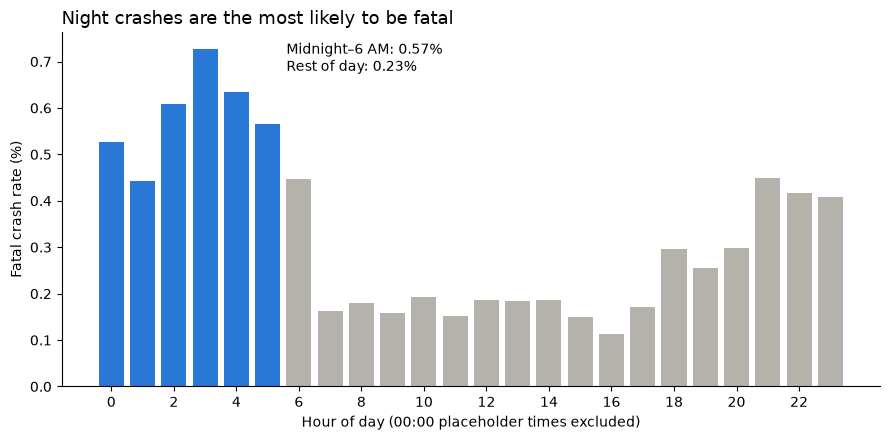

In [32]:
# night hours (0-5) in blue, the rest in gray
colors = ['#2a78d6' if hour <= 5 else '#b4b2ab' for hour in by_hour_fatal.index]

plt.figure(figsize=(9, 4.5))
plt.bar(by_hour_fatal.index, by_hour_fatal * 100, color=colors)
plt.title('Night crashes are the most likely to be fatal', loc='left', fontsize=13)
plt.xlabel('Hour of day (00:00 placeholder times excluded)')
plt.ylabel('Fatal crash rate (%)')
plt.xticks(range(0, 24, 2))
plt.text(5.6, 0.68, 'Midnight–6 AM: 0.57%\nRest of day: 0.23%', fontsize=10)
plt.gca().spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('../images/fatal_rate_by_hour.png', dpi=150)

## WHERE: severity by borough

In [22]:
borough_table = df.groupby('borough_filled').agg(
    crashes = ('injury_crash', 'size'),
    injury_rate = ('injury_crash', 'mean'),
    fatal = ('fatal_crash', 'sum'),
    fatal_rate = ('fatal_crash', 'mean')
)
borough_table

,crashes,injury_rate,fatal,fatal_rate
borough_filled,,,,
BRONX,40539,0.443351,122,0.003009
BROOKLYN,86689,0.440494,203,0.002342
MANHATTAN,45418,0.408627,118,0.002598
QUEENS,73595,0.436266,206,0.002799
STATEN ISLAND,14348,0.384304,40,0.002788


Now we test are the fatal rates across borough really different?

In [23]:
cross_table = pd.crosstab(df['borough_filled'], df['fatal_crash'])
print(cross_table)

chi2_contingency(cross_table)


fatal_crash     False  True 
borough_filled              
BRONX           40417    122
BROOKLYN        86486    203
MANHATTAN       45300    118
QUEENS          73389    206
STATEN ISLAND   14308     40


Chi2ContingencyResult(statistic=np.float64(5.877480307798734), pvalue=np.float64(0.20848686452320914), dof=4, expected_freq=array([[4.04318145e+04, 1.07185534e+02],
       [8.64597934e+04, 2.29206609e+02],
       [4.52979143e+04, 1.20085660e+02],
       [7.34004141e+04, 1.94585938e+02],
       [1.43100637e+04, 3.79362598e+01]]))

p = 0.21 > 0.05, so we fail to reject H₀: there's no evidence that the fatal rate differs across boroughs (0.23%–0.30%). This doesn't prove the rates are equal. The differences are small enough to be explained by chance. All expected counts are ≥ 37.9, so the test is valid.

## Conclusion

- **Frequency:** Crashes fell about 11% from 2023 to 2025 (96,608 → 85,559). They peak at
  evening rush (5 PM, ~17,000) and are lowest at 3 AM (~4,800), roughly tracking traffic volume.
- **Severity:** Night crashes (midnight–6 AM) are less likely to cause injury, but more likely
  to be fatal: 0.57% vs 0.23% during the day, about 2.5 times higher (z = 11.5, p < 0.001).
- **Location:** Fatal rates are similar across boroughs (0.23%–0.30%), with no significant
  difference (χ² = 5.88, p = 0.21). When a crash happens matters more than where.
- **Takeaway:** Night crashes are fewer but deadlier. Possible explanations include higher
  speeds and impaired driving, but this data can't show the cause.
- **Next:** Check whether daily fatal crash counts follow a Poisson distribution.